In [248]:
from langgraph.graph import START, StateGraph, END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict, Literal
from dotenv import load_dotenv
from pydantic import BaseModel, Field

In [249]:
load_dotenv()

True

In [250]:
model = ChatGoogleGenerativeAI(model="gemini-3-flash-preview")

In [251]:
class SentimentSchema(BaseModel):
    sentiment : Literal["positive", "negative"] = Field(description="sentiment of the review")
    

In [252]:
class DiagnosisSchema(BaseModel):
    issue_type : Literal["UX", "Performance" , "Bug", "Support", "Other"] = Field(description="The categoty of issue mentioned in the review")
    tone : Literal["angry", "frustrated", "dissapointed", "medium" , "calm"] = Field(description = "The tone of the user")
    urgency : Literal["low" , "medium" , "high"] = Field(description="How urgent or critical the issue appears to be")

In [253]:
structured_model = model.with_structured_output(SentimentSchema)

In [254]:
prompt = 'What is the sentiment of the following review - The software is too bad!'

In [255]:
class ReviewState(TypedDict):
    review : str
    sentiment : Literal["positive", "negative"]
    diagnosis : dict
    response : str

In [256]:
def find_sentiment(state : ReviewState):
    prompt = f"For the following review, find out the sentiment \n {state["review"]}"
    sentiment = structured_model.invoke(prompt).sentiment
    return {"sentiment":sentiment}


In [257]:
def sentiment_router(state : ReviewState) -> Literal["positive_response", "run_diagnosis"]:
    if state["sentiment"] == "positive":
        return "positive_response"
    else:
        return "run_diagnosis"

In [258]:
def positive_response(state : ReviewState):
    prompt = f"""Write a warm thank-you message in response to this review: {state["review"]}. Just give me one review message directly and also request the user to leave a review at the webiste."""
    response =  model.invoke(prompt)
    return {"response":response}


In [259]:
def run_diagnosis(state: ReviewState):
    prompt = f""" Diagnose this negative review: \n\n {state["review"]}\ng
                Return issue_type, tone and urgency"""
    structured_model = model.with_structured_output(DiagnosisSchema)
    response = structured_model.invoke(prompt)
    return {"diagnosis" : response.model_dump()}

    

In [260]:
def negative_response(state : ReviewState):
    diagnosis = state["diagnosis"]
    prompt = f""" You are a support assistant. The user had a '{diagnosis["issue_type"]}' issue,
        sounded '{diagnosis["tone"]}', and marked urgency '{diagnosis["urgency"]}'. Write an empathetic, helpful resolution message. Just return the message.
        """
    response = model.invoke(prompt)
    return {"response" : response}

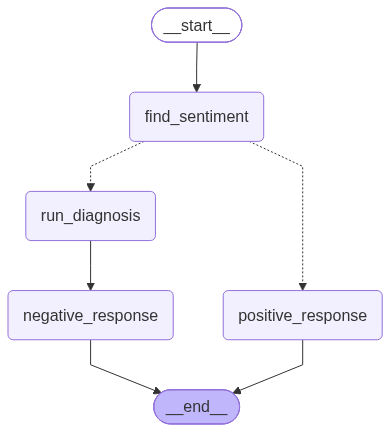

In [261]:
graph = StateGraph(ReviewState)
graph.add_node( 'find_sentiment' , find_sentiment)
graph.add_node("run_diagnosis", run_diagnosis)
graph.add_node("positive_response", positive_response)
graph.add_node("negative_response", negative_response)



graph.add_edge(START, "find_sentiment")
graph.add_conditional_edges(
    'find_sentiment',
    sentiment_router
)
graph.add_edge("positive_response", END)
graph.add_edge("run_diagnosis", "negative_response")
graph.add_edge("negative_response", END)

workflow = graph.compile()
workflow



In [262]:
intitial_state = {
    "review" : "The product was really good!"
}

workflow.invoke(intitial_state)

{'review': 'The product was really good!',
 'sentiment': 'positive',
 'response': AIMessage(content=[{'type': 'text', 'text': "Thank you so much for your kind words! We're thrilled to hear that you enjoyed the product. If you have a moment, we would love for you to share your experience by leaving a review on our website as well—it really helps us out and lets others know what to expect. Thanks again for your support!", 'extras': {'signature': 'EuYLCuMLAWkUfRNF9hVJIJnFhp8sG2cVPXHaxDzxfnbRfahjDZByCvCszVBB1ffQbT51JKjzmRsOEkWbvrIqvWXjOfrXSS2oNt5hicitBid5DudIQaypCugUqweeV0TmKC53a/NBXofKTgiBEx7FHqbNxfG30jxnCHt2LvaImz870KaAwQy5JKovbdjU4g9aUiOjW4Bq0BtaDMEgKZSObGufv0s8TMUd33git7YuaVkTL1ynZJeo2a+qbA0XH+Y0rUbDMru0MQKeglbLb2ZyADVjWr7WiF8LEBXYGGCh5VZd8t5yyjX5sdEHIEQ5qgRnUjSRy/h6qu749m+rk7hm7xa4o957TW7e6Ya99pQtS/Nzwb+LRosil43Jh3x4CkdXgYxJtJg2Jbd0AWoZLSHVTgcxCuOIqFzTxJf383eZPHKFNLrjb0zriw6MCztWd1HJPyHjNRJ2DwOkHBBgAQyYrxUViwA/AvvV09DedIyS+qpfK6jHaKBjR7Ienx7dzqdF1qPzAvAYFAtz2k8GK7/z+DG+n3tlUbikRsqFeZ3

In [263]:
initial_state = {
    "review" : "The Flash light is horrible, just two days in and it stopped working. I've also tried returning back to the shop but the shopkeeper refused to return"
}
workflow.invoke(initial_state)

KeyboardInterrupt: 